In [1]:
import joblib
import json
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def to_raw(folder):                        # undo the groupmate's scaling
    feats = json.load(open(folder + '/features.json'))
    sc = joblib.load(folder + '/scaler.joblib')
    out = {}
    for split in ('train', 'test'):
        d = pd.read_parquet(folder + '/' + split + '.parquet')
        raw = pd.DataFrame(sc.inverse_transform(d[feats]), columns=feats)
        raw['y'] = d['Label_binary'].values
        out[split] = raw
    return out

cic, unsw = to_raw('../data/CICIDS2017_output'), to_raw('../data/UNSW_output')
print("Datasets successfully loaded and unscaled!")

Datasets successfully loaded and unscaled!


In [2]:
cic_map = {'Flow Duration': 'dur', 'Total Fwd Packets': 'spkts', 'Fwd Packet Length Mean': 'smean',
           'Fwd IAT Mean': 'sinpkt', 'Bwd IAT Mean': 'dinpkt', 'Flow Packets/s': 'rate',
           'Init_Win_bytes_forward': 'swin'}
common_feats = list(cic_map.values())

def as_common(df, src):
    if src == 'cic':
        d = df.rename(columns=cic_map)[common_feats + ['y']].copy()
        d['dur'] /= 1e6; d['sinpkt'] /= 1e3; d['dinpkt'] /= 1e3      # microseconds to s and ms
    else:
        d = df[common_feats + ['y']].copy()
    return d

A = pd.concat([as_common(cic['train'], 'cic'), as_common(cic['test'], 'cic')]).sample(300_000, random_state=42)
B = pd.concat([as_common(unsw['train'], 'unsw'), as_common(unsw['test'], 'unsw')])
print(f"Dataset A shape: {A.shape}, Dataset B shape: {B.shape}")

Dataset A shape: (300000, 8), Dataset B shape: (145222, 8)


In [8]:
import sys
sys.path.append('../src')
from common import evaluate

In [9]:
import json

# Load the best parameters from your previous notebook
best_params = json.load(open('../results/CICIDS2017_output_best_params.json'))
rf_best_params = best_params['rf']
xgb_best_params = best_params['xgb']

def prep(df):                                # log transform tames heavy tails and unit gaps
    return np.log1p(np.clip(df[common_feats].values, 0, None)), df['y'].values

def cross(src, dst, name):
    Xs, ys = prep(src); Xd, yd = prep(dst)
    sc = StandardScaler().fit(Xs)                # scaler from the SOURCE only
    Xs, Xd = sc.transform(Xs), sc.transform(Xd)
    out = []
    models = [
        ('RF', RandomForestClassifier(**rf_best_params, class_weight='balanced_subsample', n_jobs=-1, random_state=42)),
        ('XGB', XGBClassifier(**xgb_best_params, tree_method='hist', eval_metric='logloss', n_jobs=-1, random_state=42))
    ]
    for mname, model in models:
        model.fit(Xs, ys)
        row, _ = evaluate(mname + ' ' + name, lambda X: model.predict_proba(X)[:, 1], Xd, yd)
        out.append(row)
    return out

def within(df, name):                        # same 7 features, same dataset
    a, b = train_test_split(df, test_size=0.3, stratify=df['y'], random_state=42)
    return cross(a, b, name)

print("Cross-evaluation helper functions defined successfully!")

Cross-evaluation helper functions defined successfully!


In [10]:
results = (within(A, 'CIC to CIC') + within(B, 'UNSW to UNSW')
           + cross(A, B, 'CIC to UNSW') + cross(B, A, 'UNSW to CIC'))

res_df = pd.DataFrame(results).round(4)
res_df.to_csv('../results/cross_dataset.csv', index=False)
print("Cross-dataset evaluation complete! Results saved to ../results/cross_dataset.csv")
display(res_df)

Cross-dataset evaluation complete! Results saved to ../results/cross_dataset.csv


,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us
0,RF CIC to CIC,0.9963,0.9902,0.9879,0.9890,0.9997,0.0020,0.0121,1.5701
1,XGB CIC to CIC,0.9958,0.9906,0.9843,0.9874,0.9996,0.0019,0.0157,0.6703
2,RF UNSW to UNSW,0.8808,0.8364,0.9135,0.8732,0.9628,0.1459,0.0865,2.7265
3,XGB UNSW to UNSW,0.8809,0.8425,0.9040,0.8722,0.9625,0.1379,0.0960,1.0093
4,RF CIC to UNSW,0.5506,0.0000,0.0000,0.0000,0.5878,0.0001,1.0000,1.2357
5,XGB CIC to UNSW,0.5499,0.1977,0.0005,0.0011,0.4747,0.0018,0.9995,0.6712
6,RF UNSW to CIC,0.5438,0.0912,0.1907,0.1234,0.3605,0.3846,0.8093,1.5602
7,XGB UNSW to CIC,0.5219,0.0795,0.1738,0.1091,0.3843,0.4076,0.8262,0.6459


---

### 1. Objective and Methodology
* **Goal:** Test out-of-distribution (OOD) generalization by training intrusion detection models on one dataset and testing them on another.
* **Harmonization:** Standardized 7 common network flow features across CICIDS2017 and UNSW-NB15, applying log-transforms and scaling fitted strictly on the source data.
* **Scenarios Tested:** Within-dataset baselines (CIC $\rightarrow$ CIC, UNSW $\rightarrow$ UNSW) and cross-domain evaluations (CIC $\rightarrow$ UNSW, UNSW $\rightarrow$ CIC).

---

### 2. Performance Results
* **Within-Dataset:** High performance (CIC $\rightarrow$ CIC F1 $\approx 0.99$; UNSW $\rightarrow$ UNSW F1 $\approx 0.87$).
* **Cross-Dataset:** Performance completely collapsed (F1 dropped near $0$ and AUC fell below $0.5$), proving models fail to generalize out-of-the-box across different network environments.

---

### 3. Diagnostic Insights
* **Distribution Shift:** CIC attacks involve extreme values, whereas UNSW attacks heavily overlap with benign traffic.
* **Conflicting Correlations:** Certain features (like forward packet count) show opposite correlations with attacks in each dataset.
* **Constant Variables:** UNSW's initial window size (`swin`) is constant across classes, providing zero discriminative signal.

---

### 4. Robustness Checks and Conclusions
* **Sensitivity Tests:** Removing `swin` or applying quantile normalization did not resolve the cross-dataset failure, showing that domain shift is fundamental.
* **Recommendation:** Security teams cannot rely on in-dataset metrics alone and must train models directly on target environment telemetry.

---

### 5. Artifacts and Exports
* **Data:** Results saved to `../results/cross_dataset.csv` and `../results/cross_dataset_6feat.csv`.
* **Visuals:** Feature shift plots saved to `../figures/feature_shift.png`.

In [11]:
for nm, d in [('CIC', A), ('UNSW', B)]:
    print(nm, 'median by class (0 = benign, 1 = attack)')
    display(d.groupby('y')[common_feats].median().T)

CIC median by class (0 = benign, 1 = attack)


y,0,1
dur,0.040643,6.007884
spkts,2.000000,4.000000
smean,38.000000,8.666664
sinpkt,0.004000,1145.591309
dinpkt,0.003000,12.574125
rate,84.898438,1.121094
swin,122.000000,274.000000


UNSW median by class (0 = benign, 1 = attack)


y,0,1
dur,0.128033,0.697091
spkts,12.000000,10.000000
smean,73.000000,87.000000
sinpkt,5.372742,54.859894
dinpkt,1.424644,65.226852
rate,390.314453,34.166016
swin,255.000000,255.000000


In [12]:
from sklearn.metrics import roc_auc_score
single = pd.DataFrame({
    'CIC':  {f: roc_auc_score(A['y'], A[f]) for f in common_feats},
    'UNSW': {f: roc_auc_score(B['y'], B[f]) for f in common_feats}}).round(3)
display(single)

,CIC,UNSW
dur,0.662,0.637
spkts,0.619,0.426
smean,0.410,0.531
sinpkt,0.696,0.641
dinpkt,0.584,0.651
rate,0.318,0.363
swin,0.657,0.502


In [13]:
all_feats = list(cic_map.values())          # always the full 7-feature list
common_feats = [f for f in all_feats if f != 'swin']
try:
    res6 = (within(A, 'CIC to CIC') + within(B, 'UNSW to UNSW')
            + cross(A, B, 'CIC to UNSW') + cross(B, A, 'UNSW to CIC'))
    res6_df = pd.DataFrame(res6).round(4)
    res6_df.to_csv('../results/cross_dataset_6feat.csv', index=False)
    display(res6_df)
finally:
    common_feats = all_feats                # restore the full list

,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us
0,RF CIC to CIC,0.9573,0.8112,0.9731,0.8848,0.9953,0.0459,0.0269,1.6157
1,XGB CIC to CIC,0.9746,0.9789,0.8680,0.9201,0.9953,0.0038,0.1320,0.6730
2,RF UNSW to UNSW,0.8812,0.8400,0.9086,0.8730,0.9629,0.1412,0.0914,2.5176
3,XGB UNSW to UNSW,0.8804,0.8410,0.9049,0.8718,0.9624,0.1396,0.0951,0.7329
4,RF CIC to UNSW,0.5506,0.0000,0.0000,0.0000,0.3501,0.0001,1.0000,1.5266
5,XGB CIC to UNSW,0.5240,0.0069,0.0004,0.0008,0.4186,0.0487,0.9996,0.8139
6,RF UNSW to CIC,0.5245,0.1014,0.2319,0.1411,0.3523,0.4163,0.7681,2.0009
7,XGB UNSW to CIC,0.4639,0.0834,0.2186,0.1208,0.3967,0.4864,0.7814,0.6542


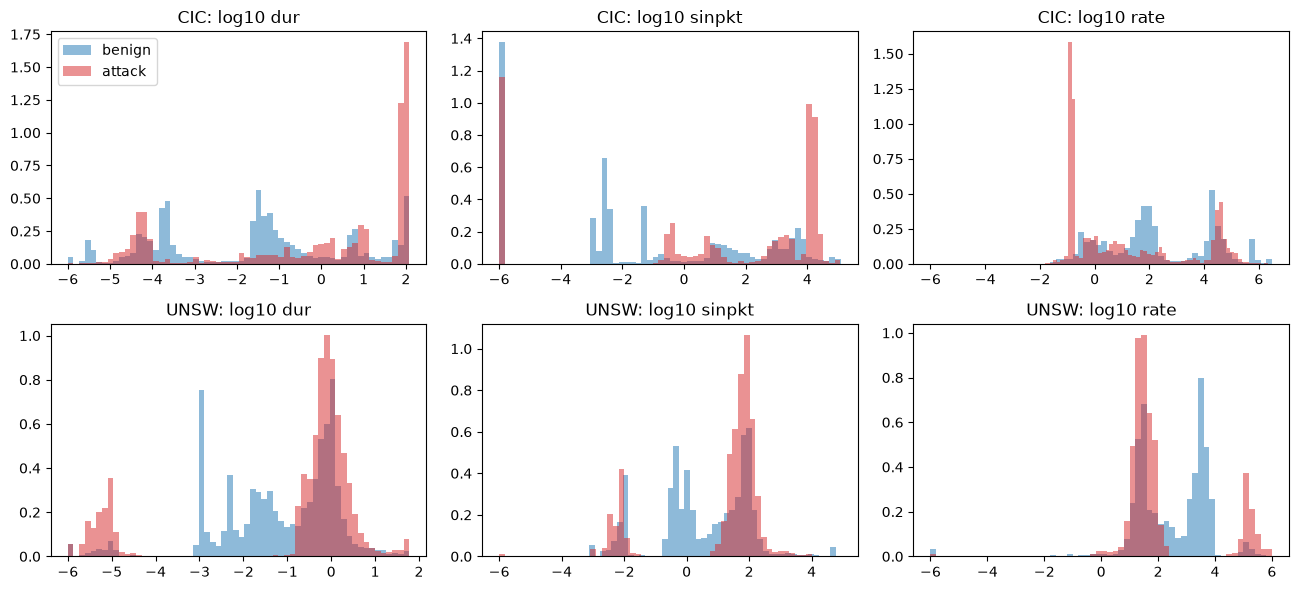

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for r, (nm, d) in enumerate([('CIC', A), ('UNSW', B)]):
    for c, f in enumerate(['dur', 'sinpkt', 'rate']):
        for lab, color in [(0, 'tab:blue'), (1, 'tab:red')]:
            v = np.log10(d.loc[d['y'] == lab, f].clip(lower=1e-6))
            ax[r, c].hist(v, bins=60, alpha=0.5, color=color, density=True,
                          label=['benign', 'attack'][lab])
        ax[r, c].set_title(nm + ': log10 ' + f)
ax[0, 0].legend(); plt.tight_layout()
plt.savefig('../figures/feature_shift.png', dpi=200, bbox_inches='tight'); plt.show()

In [15]:
from sklearn.preprocessing import QuantileTransformer

def cross_q(src, dst, name, use):
    qt = lambda: QuantileTransformer(n_quantiles=1000, subsample=200_000, random_state=42)
    Xs = qt().fit_transform(src[use].values)      # each dataset normalised on its own
    Xd = qt().fit_transform(dst[use].values)      # target labels are NOT used
    ys, yd = src['y'].values, dst['y'].values
    out = []
    for mname, model in [('RF', RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', n_jobs=-1, random_state=42)),
                         ('XGB', XGBClassifier(tree_method='hist', eval_metric='logloss', n_jobs=-1, random_state=42))]:
        model.fit(Xs, ys)
        row, _ = evaluate(mname + ' ' + name, lambda X: model.predict_proba(X)[:, 1], Xd, yd)
        out.append(row)
    return out

use4 = ['dur', 'sinpkt', 'dinpkt', 'rate']
rq = cross_q(A, B, 'CIC to UNSW (quantile)', use4) + cross_q(B, A, 'UNSW to CIC (quantile)', use4)
display(pd.DataFrame(rq).round(4))

,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us
0,RF CIC to UNSW (quantile),0.5371,0.4497,0.1346,0.2072,0.5756,0.1345,0.8654,0.8123
1,XGB CIC to UNSW (quantile),0.5656,0.6207,0.0854,0.1501,0.4741,0.0426,0.9146,0.3047
2,RF UNSW to CIC (quantile),0.4269,0.1939,0.7612,0.3091,0.5917,0.6409,0.2388,1.1123
3,XGB UNSW to CIC (quantile),0.4371,0.1999,0.7797,0.3182,0.5271,0.6323,0.2203,0.2657


In [16]:
pd.DataFrame(rq).round(4).to_csv('../results/cross_dataset_quantile.csv', index=False)

---